# Dravidian LangTech (FIRE-2025) offensive-language — imbalance experiments
| Run | Loss | Sampler | Data | Question it answers |
|---|---|---|---|---|
| R0 | CE | random | original | plain reference |
| R2 | Focal γ=2 + CB α (β=0.999) | random | original | do CB-weights help on their own? (steps 1+2) |
| R3 | Focal γ=2 + CB α | WeightedRandomSampler | original | step 4: does keeping WRS on top help or double-count? |
| R4 | Focal γ=2 + CB α | WeightedRandomSampler | + minority augmentation | step 3 |
| post-hoc | any run's saved val probabilities, `p / prior^τ` | – | – | step 5 (no retraining) |

## 0. Setup

In [39]:

!pip install -q demoji indic-transliteration

In [40]:
import os, glob
ROOT = '/kaggle/working' if os.path.isdir('/kaggle/working') else '.'
SEARCH_ROOTS = ['/kaggle/input', ROOT, '.']
# show what the notebook can see, so a wrong path is obvious
for r in SEARCH_ROOTS:
    hits = [p for p in glob.glob(f'{r}/**/*', recursive=True) if p.lower().endswith(('.csv', '.tsv', '.txt', '.xlsx', '.xls'))]
    if hits:
        print(r, '->', len(hits), 'data files, e.g.')
        for h in sorted(hits)[:25]: print('   ', h)
        break

/kaggle/input -> 15 data files, e.g.
    /kaggle/input/datasets/joannasara1111/fire-2025/FIRE-2025/FIRE-2025/Kannada/kannada_offensive_dev.csv
    /kaggle/input/datasets/joannasara1111/fire-2025/FIRE-2025/FIRE-2025/Kannada/kannada_offensive_test_without_labels.csv
    /kaggle/input/datasets/joannasara1111/fire-2025/FIRE-2025/FIRE-2025/Kannada/kannada_offensive_train.csv
    /kaggle/input/datasets/joannasara1111/fire-2025/FIRE-2025/FIRE-2025/Malayalam/Untitled-1.txt
    /kaggle/input/datasets/joannasara1111/fire-2025/FIRE-2025/FIRE-2025/Malayalam/mal_full_offensive_dev.xlsx
    /kaggle/input/datasets/joannasara1111/fire-2025/FIRE-2025/FIRE-2025/Malayalam/mal_full_offensive_train.csv
    /kaggle/input/datasets/joannasara1111/fire-2025/FIRE-2025/FIRE-2025/Malayalam/mal_offensive_test_without_labels.csv
    /kaggle/input/datasets/joannasara1111/fire-2025/FIRE-2025/FIRE-2025/Malayalam/translated_dataset (1).csv
    /kaggle/input/datasets/joannasara1111/fire-2025/FIRE-2025/FIRE-2025/Malayala

In [41]:
CFG = dict(
    language        = 'malayalam',  # 'malayalam' | 'tamil' | 'tulu'  (one language per notebook run)
    train_path      = None,         # set explicitly if auto-discovery picks the wrong file
    val_path        = None,
    val_fraction    = 0.15,         # used only when the language has no labelled dev file (Malayalam here)
    model_path      = 'setu4993/LaBSE',
    max_len         = 128,          # was 256; code-mixed comments are short, batches are trimmed dynamically anyway
    batch_size      = 32,
    eval_batch_size = 128,
    epochs          = 4,
    head_lr         = 5e-4,         # randomly initialised MLP head (was 2e-5 -> head barely learned)
    enc_lr          = 2e-5,         # top encoder layer LR; lower layers decay by llrd per layer
    llrd            = 0.9,
    weight_decay    = 0.01,
    unfreeze_schedule = {0: 1, 1: 2, 2: 4, 3: 6},   # epoch -> number of top encoder layers trainable (-1 = all 12)
    gamma           = 2.0,          # focal focusing parameter
    beta            = 0.999,        # class-balanced effective-number beta
    seeds           = [42],         # add more seeds (e.g. [42, 43, 44]) if time allows: minority val classes are tiny
    # augmentation (step 3)
    aug_ratio            = 0.25,    # minority target = aug_ratio * majority count (your 25-30%)
    aug_max_per_sample   = 6,       # max synthetic variants per original sample (diversity/duplication guard)
    aug_max_total        = 20000,   # hard cap on synthetic rows (runtime guard for free GPU)
    nllb_model           = 'facebook/nllb-200-distilled-600M',
    # preprocessing
    dedup_train          = True,
    drop_val_overlap     = True,    # remove train rows whose cleaned text also appears in val
    posthoc_tau          = 0.5,     # step 5
)
OUT_DIR = f'{ROOT}/experiments'
os.makedirs(OUT_DIR, exist_ok=True)
import json; json.dump({k: str(v) if k == 'unfreeze_schedule' else v for k, v in CFG.items()},
                       open(f'{OUT_DIR}/global_config.json', 'w'), indent=2)

In [42]:
# ===== Pure-python utilities (no torch): cleaning, loaders, metrics, weights, post-hoc, augmentation planning =====
import re, json, math, random, time, gc, unicodedata, warnings
from collections import Counter
import numpy as np, pandas as pd
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import StratifiedKFold

CLASS_NAMES = ['NOT', 'UNT', 'IND', 'GRP', 'OTH']
NUM_CLASSES = 5
LABEL_DICT = {'Not_offensive': 0, 'Offensive_Untargetede': 1,
              'Offensive_Targeted_Insult_Individual': 2,
              'Offensive_Targeted_Insult_Group': 3, 'Offensive_Targeted_Insult_Other': 4}

# ---------- text cleaning (applied identically to train / val / augmented text) ----------
try:
    import demoji
    try: demoji.download_codes()          # no-op / deprecated on newer demoji
    except Exception: pass
except Exception:
    demoji = None

_CHILLU = {'ന്‍': 'ൻ', 'ര്‍': 'ർ', 'ല്‍': 'ൽ',
           'ള്‍': 'ൾ', 'ണ്‍': 'ൺ'}     # old ZWJ chillu -> atomic chillu
_URL     = re.compile(r'https?://\S+|www\.\S+')
_MENTION = re.compile(r'@\w+')
_REPEAT  = re.compile(r'([^\W\d_])\1{2,}')                                     # sooooper -> sooper (max 2 repeats; digits untouched)

def _emoji_to_text(s):
    if demoji is None: return s
    try: found = demoji.findall(s)
    except Exception: return s
    for e, t in found.items(): s = s.replace(e, ' ' + t + ' ')
    return s

def clean_text(s):
    s = unicodedata.normalize('NFC', str(s))
    for old, new in _CHILLU.items(): s = s.replace(old, new)
    s = s.replace('‍', '').replace('‌', '').replace('﻿', '')   # stray ZWJ/ZWNJ/BOM
    s = _URL.sub(' url ', s)
    s = _MENTION.sub(' @user ', s)
    s = s.replace('#', ' ')
    s = _emoji_to_text(s)
    s = s.lower()
    s = _REPEAT.sub(r'\1\1', s)
    return ' '.join(s.split())

# ---------- loaders ----------
_norm = lambda x: str(x).strip().lower().replace(' ', '_').replace('-', '_')
LABEL_NORM = {_norm(k): v for k, v in LABEL_DICT.items()}
LABEL_NORM['offensive_untargeted'] = 1

def read_table(path):
    """Any of: .xlsx/.xls, or text with tab / comma / semicolon / pipe separator (auto-detected). No header assumed."""
    if path.lower().endswith(('.xlsx', '.xls')):
        return pd.read_excel(path, header=None, dtype=str).fillna('').astype(str), 'excel'
    with open(path, encoding='utf-8-sig', errors='replace') as f:
        head = [next(f, '') for _ in range(50)]
    head = [h for h in head if h.strip()]
    def score(d):
        c = sorted(h.count(d) for h in head)
        return (c[0] > 0, c[len(c) // 2]) if c else (False, 0)
    delim = max(['\t', ',', ';', '|'], key=score)
    df = pd.read_csv(path, sep=delim, header=None, dtype=str, engine='python', quotechar='"',
                     on_bad_lines='skip', encoding='utf-8-sig', keep_default_na=False)
    return df.astype(str), repr(delim)

def parse_fire(path, source):
    tab, how = read_table(path)
    mapped = tab.apply(lambda col: col.map(lambda v: _norm(v) in LABEL_NORM))
    lab_col = int(mapped.sum().idxmax())
    n_hit = int(mapped[lab_col].sum())
    print(f'  {os.path.basename(path)}: separator={how}, shape={tab.shape}, label column={lab_col} ({n_hit} valid labels)')
    if n_hit == 0:
        print(tab.head(5).to_string()); raise ValueError(f'no recognisable label column in {path}; first rows printed above')
    others = [c for c in tab.columns if c != lab_col]
    txt_col = max(others, key=lambda c: tab[c].str.len().mean())      # the free-text column (not ids)
    dropped = Counter(v for v in tab[lab_col] if _norm(v) not in LABEL_NORM)
    keep = tab[lab_col].map(lambda v: _norm(v) in LABEL_NORM)
    out = pd.DataFrame({'text': tab.loc[keep, txt_col].map(clean_text),
                        'label': tab.loc[keep, lab_col].map(lambda v: LABEL_NORM[_norm(v)]).astype(int),
                        'source': source}).reset_index(drop=True)
    return out[out.text.str.len() > 0].reset_index(drop=True), dropped

LANG_INFO = {   # script range, NLLB code, sanscript scheme, translation pivots (never the language itself)
    'malayalam': dict(key='mal',   nllb='mal_Mlym', lo=0x0d00, hi=0x0d7f, sans='MALAYALAM', pivots=['bt_en', 'bt_hi', 'bt_ta']),
    'tamil':     dict(key='tamil', nllb='tam_Taml', lo=0x0b80, hi=0x0bff, sans='TAMIL',     pivots=['bt_en', 'bt_hi', 'bt_ml']),
    'tulu':      dict(key='tulu',  nllb=None,       lo=0x0c80, hi=0x0cff, sans='KANNADA',   pivots=[]),   # NLLB has no Tulu
}
LANGI = LANG_INFO[CFG['language']]

def find_split(split):
    p = CFG['train_path' if split == 'train' else 'val_path']
    if p: return p
    cands = []
    for base in SEARCH_ROOTS:
        for f in glob.glob(f'{base}/**/*', recursive=True):
            n = os.path.basename(f).lower()
            if f.lower().endswith(('.csv', '.tsv', '.txt', '.xlsx', '.xls')) and LANGI['key'] in n and split in n.replace('development', 'dev'):
                cands.append(f)
        if cands: break
    if not cands: raise FileNotFoundError(f"no {CFG['language']} {split} file found - set CFG['{split}_path'] to the file path")
    cands.sort(key=lambda f: ('full' not in f.lower(), len(f)))
    if len(cands) > 1: print(f'{split}: several matches, using the first ->', cands)
    return cands[0]

# ---------- metrics ----------
def compute_metrics(y, pred):
    """Primary metric = macro-F1 over classes that actually occur in y (a class absent from val
    but predicted would otherwise add a hard 0 and reward never predicting it)."""
    present = np.unique(y)
    f1_pc = f1_score(y, pred, labels=list(range(NUM_CLASSES)), average=None, zero_division=0)
    return dict(macro_f1=float(f1_score(y, pred, labels=present, average='macro', zero_division=0)),
                macro_f1_all5=float(f1_score(y, pred, labels=list(range(NUM_CLASSES)), average='macro', zero_division=0)),
                weighted_f1=float(f1_score(y, pred, average='weighted', zero_division=0)),
                accuracy=float(accuracy_score(y, pred)),
                f1_per_class=[float(x) for x in f1_pc])

# ---------- steps 1 & 4 helpers ----------
def class_counts(labels): return np.bincount(np.asarray(labels), minlength=NUM_CLASSES)

def cb_weights(counts, beta=0.999):
    """Class-balanced weights (Cui et al. 2019): w_c = (1-beta)/(1-beta^n_c), normalised to sum to C."""
    counts = np.asarray(counts, dtype=np.float64)
    w = np.zeros_like(counts)
    ok = counts > 0
    w[ok] = (1.0 - beta) / (1.0 - np.power(beta, counts[ok]))
    w[ok] = w[ok] / w[ok].sum() * ok.sum()
    return w

def sample_weights_inv_freq(labels, counts, power=1.0):
    """power=1: full inverse-frequency (~uniform classes per batch). power=0.5: sqrt-inverse (softer, keeps more of the natural prior)."""
    labels = np.asarray(labels)
    return (1.0 / np.maximum(counts, 1).astype(np.float64) ** power)[labels]

# ---------- step 5: post-hoc prior adjustment ----------
def posthoc_scores(probs, prior, tau):
    prior = np.asarray(prior, dtype=np.float64)
    s = np.log(np.clip(probs, 1e-12, None)) - tau * np.log(np.clip(prior, 1e-12, None))     # == log(p / prior^tau)
    s[:, prior <= 0] = -np.inf          # a class with zero training prior (e.g. OTH) would otherwise get an infinite boost
    return s

def fast_macro_f1(y, pred, labels):
    f = []
    for c in labels:
        tp = np.sum((y == c) & (pred == c)); fp = np.sum((y != c) & (pred == c)); fn = np.sum((y == c) & (pred != c))
        f.append(0.0 if tp == 0 else 2 * tp / (2 * tp + fp + fn))
    return float(np.mean(f))

def bootstrap_ci(y, pred, n=1000, seed=0):
    y, pred = np.asarray(y), np.asarray(pred); labels = np.unique(y); rng = np.random.default_rng(seed)
    vals = [fast_macro_f1(y[i], pred[i], labels) for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    return np.percentile(vals, [2.5, 97.5])

def posthoc_predict(probs, prior, tau): return posthoc_scores(probs, prior, tau).argmax(1)

def tau_curve(y, probs, prior, taus):
    return {float(t): compute_metrics(y, posthoc_predict(probs, prior, t))['macro_f1'] for t in taus}

def crossfit_posthoc(y, probs, prior, taus, seeds=(0, 1, 2, 3, 4)):
    """Honest estimate of tuning tau: choose tau on one half of val, score on the other half (2-fold, repeated)."""
    y = np.asarray(y); res = []
    for sd in seeds:
        pred = np.zeros_like(y)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            for a, b in StratifiedKFold(2, shuffle=True, random_state=sd).split(probs, y):
                best = max(taus, key=lambda t: compute_metrics(y[a], posthoc_predict(probs[a], prior, t))['macro_f1'])
                pred[b] = posthoc_predict(probs[b], prior, best)
        res.append(compute_metrics(y, pred))
    return {k: (float(np.mean([r[k] for r in res])) if k != 'f1_per_class'
                else list(np.mean([r[k] for r in res], axis=0))) for k in res[0]}

# ---------- step 3: augmentation planning ----------
def script_fraction(text):
    ns = [c for c in text if not c.isspace()]
    return sum(LANGI['lo'] <= ord(c) <= LANGI['hi'] for c in ns) / max(1, len(ns))

def methods_for(source, text, cap):
    if LANGI['nllb'] is None: return []                     # Tulu: no MT model available
    if script_fraction(text) > 0.3:                         # native-script (or mixed) comments
        return (['translit'] + LANGI['pivots'] * cap)[:cap]
    return []                                               # romanised comments: NLLB cannot translate them

def plan_augmentation(df, ratio, cap, max_total, seed=42):
    rng = random.Random(seed)
    counts = class_counts(df.label)
    target = int(math.ceil(ratio * counts[0]))
    need = {c: max(0, target - int(counts[c])) for c in range(1, NUM_CLASSES)}
    tot = sum(need.values())
    if tot > max_total: need = {c: int(n * max_total / tot) for c, n in need.items()}
    rows, info = [], {}
    for c in range(1, NUM_CLASSES):
        idxs = df.index[df.label == c].tolist(); rng.shuffle(idxs)
        meths = {i: methods_for(df.at[i, 'source'], df.at[i, 'text'], cap) for i in idxs}
        goal, planned = int(need[c] * 1.1) + 1 if need[c] else 0, 0      # +10% buffer for filtered outputs
        for r in range(cap):
            for i in idxs:
                if planned >= goal: break
                if r < len(meths[i]): rows.append((i, c, meths[i][r])); planned += 1
        info[c] = dict(orig=int(counts[c]), need=need[c], planned=planned,
                       capacity=int(sum(len(v) for v in meths.values())))
    return pd.DataFrame(rows, columns=['src_idx', 'label', 'method']), info, target

# ---------- transliteration (native script -> Latin) ----------
def translit_native(text):
    from indic_transliteration import sanscript
    s = sanscript.transliterate(text, getattr(sanscript, LANGI['sans']), sanscript.ITRANS)
    for a, b in [('RRi', 'ru'), ('RRI', 'ru'), ('~N', 'ng'), ('~n', 'nj'), ('.N', 'm'), ('.n', 'm'),
                 ('A', 'aa'), ('I', 'ee'), ('U', 'oo'), ('E', 'e'), ('O', 'o'), ('M', 'm'), ('H', 'h')]:
        s = s.replace(a, b)
    return clean_text(s)

## 1. Load data, preprocess, sanity checks

In [43]:
SRC = LANGI['key']
tr_path = find_split('train')
try: va_path = find_split('dev')
except FileNotFoundError: va_path = None
print('train file:', tr_path, '\ndev file  :', va_path or '(none found -> stratified split of train)')
train_df, drop_tr = parse_fire(tr_path, SRC)
print('rows dropped by label filter (train):', dict(drop_tr))
print('\nparsed examples:'); print(train_df.head(3).to_string())
assert len(train_df) > 0, 'no rows parsed - check the label column / label strings printed above'

n0 = len(train_df)
if CFG['dedup_train']:                                     # dedup BEFORE splitting so duplicates cannot straddle train/val
    train_df = train_df.drop_duplicates(subset=['text', 'label']).reset_index(drop=True)
print(f'\nexact duplicates removed: {n0 - len(train_df)}')

if va_path:
    val_df, drop_va = parse_fire(va_path, SRC)
    print('rows dropped by label filter (val):', dict(drop_va))
    overlap = train_df.text.isin(set(val_df.text))
    print(f'train rows whose text also occurs in val: {int(overlap.sum())}')
    if CFG['drop_val_overlap']: train_df = train_df[~overlap].reset_index(drop=True)
else:
    from sklearn.model_selection import train_test_split
    cnt = class_counts(train_df.label)
    strat = train_df.label if cnt[cnt > 0].min() >= 2 else None
    train_df, val_df = train_test_split(train_df, test_size=CFG['val_fraction'], random_state=42, stratify=strat)
    train_df, val_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True)
    val_df.to_csv(f'{OUT_DIR}/my_val_split.csv', index=False)      # frozen copy of the split used by every run
    print(f"no labelled dev file: carved {len(val_df)} rows ({CFG['val_fraction']:.0%}) from train as validation "
          f"(test file has no labels). Scores are NOT comparable with the official dev set.")
assert len(val_df) > 0
val_df = val_df.reset_index(drop=True)

stats = pd.DataFrame({'train_total': class_counts(train_df.label), 'val': class_counts(val_df.label)}, index=CLASS_NAMES)
print(f'native-script share of train rows (augmentable): {(train_df.text.map(script_fraction) > 0.3).mean():.1%}')
stats['train_%'] = (stats.train_total / stats.train_total.sum() * 100).round(2)
print('\n', stats.to_string())
stats.to_csv(f'{OUT_DIR}/data_stats.csv')
PRIOR = class_counts(train_df.label) / len(train_df)      # natural class prior, used by post-hoc step for every run
print('\nCB weights (beta=%.3f):' % CFG['beta'], dict(zip(CLASS_NAMES, cb_weights(class_counts(train_df.label), CFG['beta']).round(3))))

train file: /kaggle/input/datasets/joannasara1111/fire-2025/FIRE-2025/FIRE-2025/Malayalam/mal_full_offensive_train.csv 
dev file  : /kaggle/input/datasets/joannasara1111/fire-2025/FIRE-2025/FIRE-2025/Malayalam/mal_full_offensive_dev.xlsx
  mal_full_offensive_train.csv: separator=',', shape=(16011, 2), label column=1 (14723 valid labels)
rows dropped by label filter (train): {'Labels': 1, 'not-malayalam': 1287}

parsed examples:
                                                                                                                                        text  label source
0                                                                                 പലദേശം. പല ഭാഷ ഒരേ ഒരു രാജാവ് അല്ലാതെ സ്വന്തം രാജവയത് അല്ല      0    mal
1                                                                                   ഈ ഓണം ഏട്ടനും പിള്ളേർക്ക് ഉള്ളതാണ് എന്ന് ഉള്ളവർ ലൈക് അടി      0    mal
2  ആരണ്ട ആരണ്ട തലുണ്ടാകാണാ ആരണ്ട ഞാൻ ആണ്ട ഞാൻ ആണ്ട ഞാൻ royal mech ആടാ ആരണ്ട ആരണ്ട മീശ പിരിക്കുന്ന ആരണ്ട

## 2. Model, losses, training engine (torch)

In [44]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, WeightedRandomSampler
from transformers import AutoModel, AutoTokenizer, get_linear_schedule_with_warmup
from torch.optim import AdamW
from tqdm.auto import tqdm

device   = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_cuda = device.type == 'cuda'
if use_cuda:
    major = torch.cuda.get_device_capability()[0]
    AMP_DTYPE = torch.bfloat16 if major >= 8 else torch.float16     # T4/P100 have no real bf16 -> fp16 + GradScaler
else:
    AMP_DTYPE = torch.float32
USE_FP16_SCALER = use_cuda and AMP_DTYPE == torch.float16
print('device:', device, '| amp dtype:', AMP_DTYPE, '| GPUs visible:', torch.cuda.device_count())

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if use_cuda: torch.cuda.manual_seed_all(s)

TOKENIZER = AutoTokenizer.from_pretrained(CFG['model_path'])
_tok_cache = {}
def encode(df, key):
    if key in _tok_cache: return _tok_cache[key]
    enc = TOKENIZER(df.text.tolist(), padding='max_length', truncation=True,
                    max_length=CFG['max_len'], return_tensors='pt')
    out = (enc['input_ids'], enc['attention_mask'], torch.tensor(df.label.values, dtype=torch.long))
    _tok_cache[key] = out; return out

class Embedding(nn.Module):
    def __init__(self, model_path):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_path)
        self.dropout = nn.Dropout(0.3)
        self.out_dim = self.encoder.config.hidden_size * 3
    def forward(self, ids, mask):
        out = self.encoder(input_ids=ids, attention_mask=mask).last_hidden_state.float()
        m = mask.unsqueeze(-1).float()
        mean = (out * m).sum(1) / m.sum(1).clamp(min=1.0)             # mask-aware (original pooled over [PAD] too)
        mx   = out.masked_fill(m == 0, -1e4).max(1).values
        return self.dropout(torch.cat([out[:, 0], mean, mx], 1))

class Classifier(nn.Module):
    def __init__(self, input_size, hidden_size=256, num_classes=5, p=0.3):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size);  self.ln1 = nn.LayerNorm(hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size // 2); self.ln2 = nn.LayerNorm(hidden_size // 2)
        self.fc3 = nn.Linear(hidden_size // 2, num_classes)
        self.drop = nn.Dropout(p)
    def forward(self, x):
        x = self.drop(F.relu(self.ln1(self.fc1(x))))
        x = self.drop(F.relu(self.ln2(self.fc2(x))))
        return self.fc3(x)

class Model(nn.Module):
    def __init__(self, model_path):
        super().__init__()
        self.embed = Embedding(model_path)
        self.classifier = Classifier(self.embed.out_dim)
        for p in self.embed.encoder.parameters(): p.requires_grad = False
    def forward(self, ids, mask): return self.classifier(self.embed(ids, mask))

def set_trainable_layers(model, n):
    """Train the top-n encoder layers (-1 = all 12). The 500k-token word-embedding matrix always stays frozen."""
    enc = model.embed.encoder
    for p in enc.parameters(): p.requires_grad = False
    layers = enc.encoder.layer
    sel = layers if (n == -1 or n >= len(layers)) else (layers[-n:] if n > 0 else [])
    for l in sel:
        for p in l.parameters(): p.requires_grad = True
    return len(sel)

def build_optimizer(model, cfg):
    """One optimizer over head + all encoder layers (layer-wise LR decay). Frozen params simply have no grad,
    so unfreezing later needs no optimizer rebuild and the LR schedule stays continuous."""
    groups = []
    def add(params, lr):
        d  = [p for p in params if p.ndim > 1]; nd = [p for p in params if p.ndim <= 1]
        if d:  groups.append(dict(params=d,  lr=lr, weight_decay=cfg['weight_decay']))
        if nd: groups.append(dict(params=nd, lr=lr, weight_decay=0.0))
    add(list(model.classifier.parameters()), cfg['head_lr'])
    L = len(model.embed.encoder.encoder.layer)
    for i, layer in enumerate(model.embed.encoder.encoder.layer):
        add(list(layer.parameters()), cfg['enc_lr'] * cfg['llrd'] ** (L - 1 - i))
    return AdamW(groups, eps=1e-8)

class FocalLoss(nn.Module):
    """FL = -alpha_t (1-p_t)^gamma log p_t ; p_t comes from the UNWEIGHTED softmax (the original used the
    class-weighted CE to compute p_t, which distorts the focusing term). alpha=None, gamma=0 -> plain CE."""
    def __init__(self, alpha=None, gamma=2.0):
        super().__init__()
        self.gamma = gamma
        self.register_buffer('alpha', None if alpha is None else torch.as_tensor(alpha, dtype=torch.float32))
    def forward(self, logits, targets):
        logpt = F.log_softmax(logits.float(), -1).gather(1, targets[:, None]).squeeze(1)
        loss = -((1 - logpt.exp()) ** self.gamma) * logpt
        if self.alpha is not None: loss = loss * self.alpha[targets]
        return loss.mean()

def amp_ctx(): return torch.autocast(device_type=device.type, dtype=AMP_DTYPE, enabled=use_cuda)

@torch.no_grad()
def predict_probs(model, ids, mask, bs):
    model.eval(); out = []
    for i in range(0, len(ids), bs):
        m = mask[i:i + bs]; L = int(m.sum(1).max())
        with amp_ctx():
            logits = model(ids[i:i + bs, :L].to(device), m[:, :L].to(device))
        out.append(F.softmax(logits.float(), -1).cpu())
    return torch.cat(out).numpy()

device: cuda | amp dtype: torch.float16 | GPUs visible: 2


In [45]:
def run_experiment(name, loss_kind, use_wrs, train_data, seed=42, cfg=CFG, force=False, wrs_power=1.0):
    """loss_kind: 'ce' | 'focal' | 'cb_focal'.  Everything is written to experiments/<name>_s<seed>/."""
    run_dir = f'{OUT_DIR}/{name}_s{seed}'
    if os.path.exists(f'{run_dir}/done.json') and not force:
        print(f'[skip] {name} seed {seed} already finished'); return json.load(open(f'{run_dir}/done.json'))
    os.makedirs(run_dir, exist_ok=True); t0 = time.time()
    seed_everything(seed)

    tr_ids, tr_mask, tr_y = encode(train_data, f'train_{id(train_data)}')
    va_ids, va_mask, va_y = encode(val_df, 'val')
    counts  = class_counts(tr_y.numpy());  cbw = cb_weights(counts, cfg['beta'])
    if loss_kind == 'ce':         criterion = nn.CrossEntropyLoss()
    elif loss_kind == 'focal':    criterion = FocalLoss(None, cfg['gamma'])
    elif loss_kind == 'cb_focal': criterion = FocalLoss(cbw, cfg['gamma'])
    else: raise ValueError(loss_kind)
    criterion = criterion.to(device)

    g = torch.Generator().manual_seed(seed)
    ds = TensorDataset(tr_ids, tr_mask, tr_y)
    if use_wrs:
        sw = torch.as_tensor(sample_weights_inv_freq(tr_y.numpy(), counts, wrs_power), dtype=torch.double)
        loader = DataLoader(ds, batch_size=cfg['batch_size'], pin_memory=use_cuda,
                            sampler=WeightedRandomSampler(sw, num_samples=len(ds), replacement=True, generator=g))
    else:
        loader = DataLoader(ds, batch_size=cfg['batch_size'], shuffle=True, generator=g, pin_memory=use_cuda)

    json.dump(dict(name=name, seed=seed, loss=loss_kind, wrs=use_wrs, wrs_power=wrs_power, n_train=len(ds),
                   train_counts=counts.tolist(), cb_weights=[float(x) for x in cbw], cfg={k: str(v) for k, v in cfg.items()}),
              open(f'{run_dir}/config.json', 'w'), indent=2)
    print(f'\n=== {name} (seed {seed}) | loss={loss_kind} wrs={use_wrs} | n_train={len(ds)} | counts={counts.tolist()}')
    if loss_kind == 'cb_focal': print('    CB alpha:', np.round(cbw, 3).tolist())

    model = Model(cfg['model_path']).to(device)
    optimizer = build_optimizer(model, cfg)
    total = len(loader) * cfg['epochs']
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total), total)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_FP16_SCALER)

    history, best, best_ep = [], -1.0, -1
    for ep in range(cfg['epochs']):
        if ep in cfg['unfreeze_schedule']:
            print(f'    epoch {ep+1}: training top {set_trainable_layers(model, cfg["unfreeze_schedule"][ep])} encoder layers')
        model.train(); run_loss = 0.0
        for ids, mask, y in tqdm(loader, desc=f'{name} ep{ep+1}', leave=False):
            L = int(mask.sum(1).max())
            ids, mask, y = ids[:, :L].to(device, non_blocking=True), mask[:, :L].to(device, non_blocking=True), y.to(device, non_blocking=True)
            with amp_ctx(): logits = model(ids, mask)
            loss = criterion(logits.float(), y)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()
            run_loss += loss.item()
        probs = predict_probs(model, va_ids, va_mask, cfg['eval_batch_size'])
        m = compute_metrics(va_y.numpy(), probs.argmax(1))
        history.append(dict(epoch=ep + 1, train_loss=run_loss / len(loader), **m))
        np.save(f'{run_dir}/val_probs_ep{ep+1}.npy', probs)
        json.dump(history, open(f'{run_dir}/history.json', 'w'), indent=2)
        print(f'    ep{ep+1}: loss {run_loss/len(loader):.4f} | macroF1 {m["macro_f1"]:.4f} | acc {m["accuracy"]:.4f} | per-class {np.round(m["f1_per_class"], 3).tolist()}')
        if m['macro_f1'] > best:
            best, best_ep = m['macro_f1'], ep + 1
            names = {n for n, p in model.named_parameters() if p.requires_grad}
            torch.save({k: v.detach().cpu() for k, v in model.state_dict().items() if k in names}, f'{run_dir}/best_trainable.pt')
            np.save(f'{run_dir}/best_val_probs.npy', probs)

    probs = np.load(f'{run_dir}/best_val_probs.npy'); y = va_y.numpy(); pred = probs.argmax(1)
    np.save(f'{run_dir}/y_val.npy', y)
    pd.DataFrame(confusion_matrix(y, pred, labels=range(NUM_CLASSES)), index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(f'{run_dir}/confusion_matrix.csv')
    open(f'{run_dir}/report.txt', 'w').write(classification_report(y, pred, labels=list(range(NUM_CLASSES)), target_names=CLASS_NAMES, zero_division=0))
    res = dict(name=name, seed=seed, best_epoch=best_ep, minutes=round((time.time() - t0) / 60, 1),
               **compute_metrics(y, pred))
    json.dump(res, open(f'{run_dir}/done.json', 'w'), indent=2)
    print(f'    >>> best epoch {best_ep}: macroF1 {res["macro_f1"]:.4f} ({res["minutes"]} min). Saved to {run_dir}')
    del model, optimizer, scheduler; gc.collect()
    if use_cuda: torch.cuda.empty_cache()
    return res

## 3. Experiments

In [46]:
# R0 - plain cross-entropy, random sampling (reference)
for s in CFG['seeds']: run_experiment('R0_ce', 'ce', False, train_df, seed=s)

[skip] R0_ce seed 42 already finished


In [47]:
# R1 - your current notebook: Focal(gamma=2, no alpha) + WeightedRandomSampler
for s in CFG['seeds']: run_experiment('R1_focal_wrs', 'focal', True, train_df, seed=s)

[skip] R1_focal_wrs seed 42 already finished


In [48]:
# R2 - steps 1+2: class-balanced alpha (beta=0.999) inside Focal(gamma=2), random sampling
for s in CFG['seeds']: run_experiment('R2_cbfocal', 'cb_focal', False, train_df, seed=s)

[skip] R2_cbfocal seed 42 already finished


In [49]:
# R3 - steps 1+2+4: CB-Focal + WeightedRandomSampler retained
for s in CFG['seeds']: run_experiment('R3_cbfocal_wrs', 'cb_focal', True, train_df, seed=s)

[skip] R3_cbfocal_wrs seed 42 already finished


### Step 3 - targeted minority augmentation (classes 1-4)
Only the **training** split is augmented. Methods: back-translation through NLLB-200 (native-script comments via English / Hindi / third-language pivots, noisy sampling on the way back)
and native-script->Latin transliteration. Romanised comments (Manglish/Tanglish) cannot be translated by NLLB and are not augmented; Tulu has no NLLB support, so R4 equals R3 for it.
The achieved ratio per class is reported honestly -
if it is below 25% the cap (`aug_max_per_sample`) or the pool of augmentable rows was the limit.

In [50]:
from transformers import AutoModelForSeq2SeqLM
AUG_DIR = f'{OUT_DIR}/augmentation'; os.makedirs(AUG_DIR, exist_ok=True)
NLLB = dict(en='eng_Latn', hi='hin_Deva', ml='mal_Mlym', ta='tam_Taml')
PIVOT = {'bt_hi': NLLB['hi'], 'bt_ta': NLLB['ta'], 'bt_ml': NLLB['ml'], 'bt_en': NLLB['en']}

@torch.no_grad()
def nllb_translate(texts, src, tgt, tok, nm, sample=False, bs=64):
    tok.src_lang = src
    order = sorted(range(len(texts)), key=lambda i: len(texts[i])); out = [''] * len(texts)
    kw = dict(do_sample=True, top_p=0.9, temperature=0.8) if sample else dict(do_sample=False, num_beams=1)
    for i in tqdm(range(0, len(order), bs), desc=f'{src}->{tgt}', leave=False):
        idx = order[i:i + bs]
        enc = tok([texts[j] for j in idx], return_tensors='pt', padding=True, truncation=True, max_length=96).to(device)
        gen = nm.generate(**enc, forced_bos_token_id=tok.convert_tokens_to_ids(tgt), max_new_tokens=96, **kw)
        for j, t in zip(idx, tok.batch_decode(gen, skip_special_tokens=True)): out[j] = t
    return out

def build_augmented(df, cfg=CFG):
    final_path = f'{AUG_DIR}/train_augmented.csv'
    if os.path.exists(final_path):
        print('[skip] loading cached augmented set'); return pd.read_csv(final_path, keep_default_na=False)
    if LANGI['nllb'] is None:
        print('Augmentation is not available for this language (no MT model); R4 will equal R3.'); return df
    plan, info, target = plan_augmentation(df, cfg['aug_ratio'], cfg['aug_max_per_sample'], cfg['aug_max_total'])
    plan.to_csv(f'{AUG_DIR}/plan.csv', index=False)
    print(f'majority={int(class_counts(df.label)[0])}  target per minority class={target}')
    for c, d in info.items(): print(f'  {CLASS_NAMES[c]}: have {d["orig"]}, need +{d["need"]}, planned {d["planned"]} (augmentable capacity {d["capacity"]})')

    synth = []
    need_gen = plan[plan.method != 'translit']
    tok = nm = None
    if len(need_gen):
        tok = AutoTokenizer.from_pretrained(cfg['nllb_model'])
        nm = AutoModelForSeq2SeqLM.from_pretrained(cfg['nllb_model'], torch_dtype=torch.float16 if use_cuda else torch.float32).to(device).eval()
    seed_everything(42)
    for method, g in plan.groupby('method'):
        source = SRC
        cache = f'{AUG_DIR}/gen_{method}_{source}.csv'
        if os.path.exists(cache): part = pd.read_csv(cache, keep_default_na=False)
        else:
            src_texts = df.text.loc[g.src_idx].tolist()
            if method == 'translit':
                outs, last_err = [], None
                for t in src_texts:
                    try: outs.append(translit_native(t))
                    except Exception as e: outs.append(''); last_err = e
                nfail = sum(o == '' for o in outs)
                if nfail: print(f'    WARNING: {nfail}/{len(outs)} transliterations failed (is indic-transliteration installed?): {last_err}')
            else:
                uniq = sorted(set(g.src_idx)); piv = nllb_translate(df.text.loc[uniq].tolist(), LANGI['nllb'], PIVOT[method], tok, nm, sample=False)
                piv = dict(zip(uniq, piv))
                outs = nllb_translate([piv[i] for i in g.src_idx], PIVOT[method], LANGI['nllb'], tok, nm, sample=True)
            part = pd.DataFrame(dict(src_idx=g.src_idx.values, label=g.label.values, method=method, source=source,
                                     text=[clean_text(o) for o in outs]))
            part.to_csv(cache, index=False)
        synth.append(part)
    if nm is not None:
        del nm, tok; gc.collect(); torch.cuda.empty_cache()

    synth = pd.concat(synth, ignore_index=True)
    n_raw = len(synth)
    src_text = synth.src_idx.map(df.text)
    ratio_len = synth.text.str.split().str.len() / src_text.str.split().str.len().clip(lower=1)
    keep = (synth.text.str.len() >= 3) & (synth.text != src_text)
    keep &= (synth.method == 'translit') | ((ratio_len > 0.4) & (ratio_len < 2.5))
    synth = synth[keep]
    synth = synth[~synth.text.isin(set(df.text))].drop_duplicates(subset=['text']).reset_index(drop=True)
    print(f'synthetic rows: generated {n_raw} -> kept {len(synth)} after quality/dup filters')
    for m in synth.method.unique():
        print(f'--- sample outputs: {m}')
        for _, r in synth[synth.method == m].head(3).iterrows(): print('   src:', df.text[r.src_idx][:90], '\n   aug:', r.text[:90])

    out = pd.concat([df.assign(method='orig', src_idx=-1), synth[['text', 'label', 'source', 'method', 'src_idx']]], ignore_index=True)
    out.to_csv(final_path, index=False)
    c0, c1 = class_counts(df.label), class_counts(out.label)
    summ = pd.DataFrame({'original': c0, 'augmented': c1, 'ratio_to_majority': (c1 / c1[0]).round(3)}, index=CLASS_NAMES)
    summ.to_csv(f'{AUG_DIR}/aug_summary.csv'); print(summ.to_string())
    return out

train_aug_df = build_augmented(train_df)

[skip] loading cached augmented set


In [51]:
# R4 - steps 1+2+3+4: CB-Focal + WRS + augmented minority classes (CB alpha and sampler weights recomputed on the augmented counts)
for s in CFG['seeds']: run_experiment('R4_cbfocal_wrs_aug', 'cb_focal', True, train_aug_df, seed=s)

[skip] R4_cbfocal_wrs_aug seed 42 already finished


### Follow-up runs (added after the first results: full WeightedRandomSampler hurt)
R4b tests augmentation **without** the sampler (R4 was confounded by it); R5 keeps a *softer* sampler (sqrt-inverse frequency).

In [52]:
# R4b - CB-Focal + augmentation, random sampling (fair test of step 3)
for s in CFG['seeds']: run_experiment('R4b_cbfocal_aug', 'cb_focal', False, train_aug_df, seed=s)

[skip] R4b_cbfocal_aug seed 42 already finished


In [53]:
# R5 - CB-Focal + soft WeightedRandomSampler (sqrt-inverse frequency), original data
for s in CFG['seeds']: run_experiment('R5_cbfocal_softwrs', 'cb_focal', True, train_df, seed=s, wrs_power=0.5)

[skip] R5_cbfocal_softwrs seed 42 already finished


## 4. Step 5 - post-hoc prior adjustment (no retraining) and comparison
`p_adj = p / prior^τ` is applied to the saved validation probabilities of **every** run. `prior` = natural training class frequencies.
Three numbers per run: raw argmax, fixed τ=0.5 (your spec), and a **cross-fitted** τ (τ picked on one half of val, scored on the other half) -
the last one is the honest estimate of what tuning τ buys. Note that runs using WeightedRandomSampler already see a ~uniform effective prior,
so a large τ may over-correct for them; the τ-curve shows this.

In [54]:
import matplotlib; import matplotlib.pyplot as plt
TAUS = [round(t, 2) for t in np.arange(0, 1.51, 0.1)]
rows, curves = [], {}
for d in sorted(glob.glob(f'{OUT_DIR}/R*_s*/done.json')):
    rd = os.path.dirname(d); cfgj = json.load(open(f'{rd}/config.json')); name = f"{cfgj['name']}_s{cfgj['seed']}"
    y = np.load(f'{rd}/y_val.npy'); P = np.load(f'{rd}/best_val_probs.npy')
    variants = {'raw': P.argmax(1), f'posthoc tau={CFG["posthoc_tau"]}': posthoc_predict(P, PRIOR, CFG['posthoc_tau'])}
    for v, pr in variants.items():
        ci = dict(zip(['ci_lo', 'ci_hi'], bootstrap_ci(y, pr))) if v == 'raw' else {}
        rows.append(dict(run=name, variant=v, **compute_metrics(y, pr), **ci))
    cf = crossfit_posthoc(y, P, PRIOR, TAUS); rows.append(dict(run=name, variant='posthoc tau cross-fit', **cf))
    curves[name] = tau_curve(y, P, PRIOR, TAUS)
res = pd.DataFrame(rows)
for i, c in enumerate(CLASS_NAMES): res[f'F1_{c}'] = res.f1_per_class.map(lambda v: v[i])
res = res.drop(columns='f1_per_class')
res.to_csv(f'{OUT_DIR}/summary_all_variants.csv', index=False)
pd.set_option('display.width', 220)
print('val support per class:', dict(zip(CLASS_NAMES, class_counts(val_df.label).tolist())))
print(res.round(4).to_string(index=False))

val support per class: {'NOT': 1779, 'UNT': 20, 'IND': 24, 'GRP': 13, 'OTH': 0}
                   run               variant  macro_f1  macro_f1_all5  weighted_f1  accuracy  ci_lo  ci_hi  F1_NOT  F1_UNT  F1_IND  F1_GRP  F1_OTH
             R0_ce_s42                   raw    0.3858         0.3086       0.9584    0.9668 0.2956 0.4599  0.9839  0.2927  0.0000  0.2667     0.0
             R0_ce_s42       posthoc tau=0.5    0.4264         0.3411       0.9476    0.9406    NaN    NaN  0.9705  0.3000  0.1493  0.2857     0.0
             R0_ce_s42 posthoc tau cross-fit    0.4019         0.3215       0.9466    0.9395    NaN    NaN  0.9702  0.2945  0.1519  0.1911     0.0
      R1_focal_wrs_s42                   raw    0.3135         0.2508       0.8867    0.8328 0.2770 0.3525  0.9115  0.1231  0.0964  0.1231     0.0
      R1_focal_wrs_s42       posthoc tau=0.5    0.2043         0.1634       0.6401    0.4918    NaN    NaN  0.6589  0.0575  0.0523  0.0485     0.0
      R1_focal_wrs_s42 posthoc tau cro

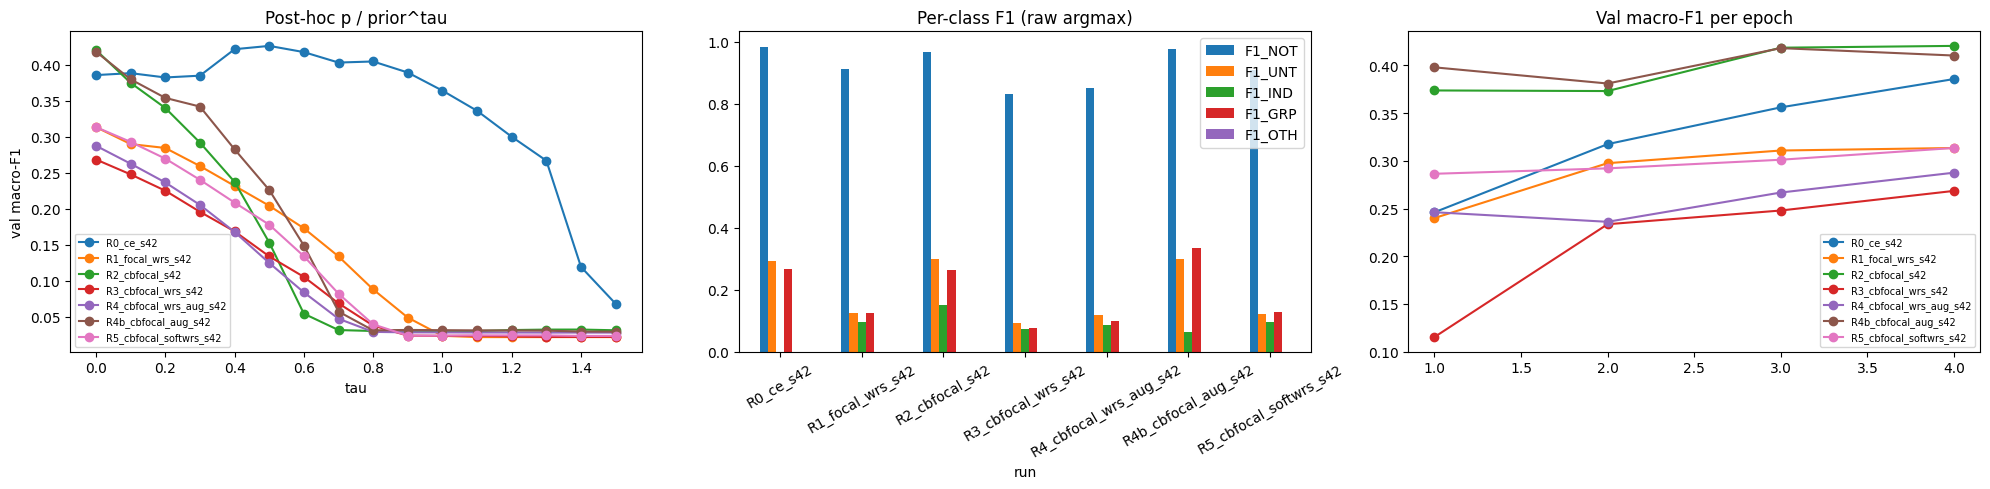

                                         macro_f1     macro_f1_all5     weighted_f1     accuracy    
                                             mean std          mean std        mean std     mean std
config             variant                                                                          
R0_ce              posthoc tau cross-fit   0.4019 NaN        0.3215 NaN      0.9466 NaN   0.9395 NaN
                   posthoc tau=0.5         0.4264 NaN        0.3411 NaN      0.9476 NaN   0.9406 NaN
                   raw                     0.3858 NaN        0.3086 NaN      0.9584 NaN   0.9668 NaN
R1_focal_wrs       posthoc tau cross-fit   0.3135 NaN        0.2508 NaN      0.8867 NaN   0.8328 NaN
                   posthoc tau=0.5         0.2043 NaN        0.1634 NaN      0.6401 NaN   0.4918 NaN
                   raw                     0.3135 NaN        0.2508 NaN      0.8867 NaN   0.8328 NaN
R2_cbfocal         posthoc tau cross-fit   0.4205 NaN        0.3364 NaN      0.9446 NaN   0

In [55]:
# Plots: tau curves, per-class F1 of raw predictions, training curves
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
for n, c in curves.items(): ax[0].plot(list(c), list(c.values()), marker='o', label=n)
ax[0].set_xlabel('tau'); ax[0].set_ylabel('val macro-F1'); ax[0].set_title('Post-hoc p / prior^tau'); ax[0].legend(fontsize=7)
raw = res[res.variant == 'raw'].set_index('run')[[f'F1_{c}' for c in CLASS_NAMES]]
raw.plot.bar(ax=ax[1], rot=30); ax[1].set_title('Per-class F1 (raw argmax)')
for d in sorted(glob.glob(f'{OUT_DIR}/R*_s*/history.json')):
    h = json.load(open(d)); ax[2].plot([e['epoch'] for e in h], [e['macro_f1'] for e in h], marker='o', label=os.path.basename(os.path.dirname(d)))
ax[2].set_title('Val macro-F1 per epoch'); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/comparison.png', dpi=130); plt.show()

# seed-averaged leaderboard + decision helper
res['config'] = res.run.str.replace(r'_s\d+$', '', regex=True)
board = res.groupby(['config', 'variant'])[['macro_f1', 'macro_f1_all5', 'weighted_f1', 'accuracy']].agg(['mean', 'std']).round(4)
board.to_csv(f'{OUT_DIR}/leaderboard.csv'); print(board.to_string())
best = res.groupby(['config', 'variant']).macro_f1.mean().sort_values(ascending=False)
print('\nTop 5 (config, variant) by mean val macro-F1:'); print(best.head(5).round(4).to_string())
print('\nCaution: with one seed and a few dozen val samples in the smallest classes, differences below ~1 macro-F1 point are within noise. '
      'Raise CFG["seeds"] before trusting a small gap, and note the checkpoint epoch + tau are selected on the same val set.')

## 5. Is the gap real? Paired bootstrap + where the errors go
Paired bootstrap resamples the *same* validation rows for both runs, so it is much more sensitive than comparing overlapping CIs.
If the interval contains 0, call the two runs tied and choose by simplicity.

In [56]:
def paired_boot(a, b, n=2000, seed=0):
    ra, rb = f'{OUT_DIR}/{a}', f'{OUT_DIR}/{b}'
    y  = np.load(f'{ra}/y_val.npy')
    pa = np.load(f'{ra}/best_val_probs.npy').argmax(1); pb = np.load(f'{rb}/best_val_probs.npy').argmax(1)
    labels, rng, d = np.unique(y), np.random.default_rng(seed), []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        d.append(fast_macro_f1(y[i], pa[i], labels) - fast_macro_f1(y[i], pb[i], labels))
    d = np.array(d)
    return dict(mean_diff=round(float(d.mean()), 4), ci95=np.percentile(d, [2.5, 97.5]).round(3).tolist(), p_a_better=round(float((d > 0).mean()), 3))

PAIRS = [('R2_cbfocal_s42', 'R0_ce_s42'), ('R4b_cbfocal_aug_s42', 'R2_cbfocal_s42'), ('R2_cbfocal_s42', 'R1_focal_wrs_s42')]
for a, b in PAIRS:
    if os.path.exists(f'{OUT_DIR}/{a}/done.json') and os.path.exists(f'{OUT_DIR}/{b}/done.json'):
        print(f'{a}  vs  {b}:', paired_boot(a, b))

# where do the IND / UNT / GRP errors go? (rows = true class, cols = predicted)
for r in ['R0_ce_s42', 'R2_cbfocal_s42']:
    p = f'{OUT_DIR}/{r}/confusion_matrix.csv'
    if os.path.exists(p): print(f'\n{r}'); print(pd.read_csv(p, index_col=0).to_string())

R2_cbfocal_s42  vs  R0_ce_s42: {'mean_diff': 0.0384, 'ci95': [-0.044, 0.121], 'p_a_better': 0.82}
R4b_cbfocal_aug_s42  vs  R2_cbfocal_s42: {'mean_diff': -0.0034, 'ci95': [-0.044, 0.039], 'p_a_better': 0.424}
R2_cbfocal_s42  vs  R1_focal_wrs_s42: {'mean_diff': 0.1049, 'ci95': [0.063, 0.153], 'p_a_better': 1.0}

R0_ce_s42
      NOT  UNT  IND  GRP  OTH
NOT  1767   12    0    0    0
UNT    14    6    0    0    0
IND    23    1    0    0    0
GRP     9    2    0    2    0
OTH     0    0    0    0    0

R2_cbfocal_s42
      NOT  UNT  IND  GRP  OTH
NOT  1697   27   36   19    0
UNT     9    9    1    1    0
IND    16    3    5    0    0
GRP     7    1    0    5    0
OTH     0    0    0    0    0


## 6. Binary view: all offensive classes merged (NOT vs OFF)
No retraining: each saved 5-class model is scored as a binary detector with OFF = UNT + IND + GRP + OTH (score = 1 - P(NOT)).
Variants per run: (a) 5-class argmax then merged, (b) post-hoc p/prior^tau then merged, (c) P(OFF) > 0.5,
(d) P(OFF) threshold tuned on one half of val and scored on the other half (honest), (e) best threshold on all of val (**optimistic**, shown for reference only).
The "best" model is picked among (a)-(d).

In [57]:
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, precision_recall_fscore_support
BIN_DIR = f'{OUT_DIR}/binary'; os.makedirs(BIN_DIR, exist_ok=True)
THR_GRID = np.round(np.arange(0.02, 0.98, 0.02), 2)

def bin_metrics(yb, pb):
    p, r, f, _ = precision_recall_fscore_support(yb, pb, labels=[0, 1], zero_division=0)
    return dict(macro_f1=float(f.mean()), f1_OFF=float(f[1]), prec_OFF=float(p[1]), rec_OFF=float(r[1]),
                f1_NOT=float(f[0]), accuracy=float((yb == pb).mean()))

def best_thr(yb, s):
    return max(THR_GRID, key=lambda t: bin_metrics(yb, (s > t).astype(int))['macro_f1'])

def crossfit_thr_pred(yb, s, seed=0):
    pred = np.zeros_like(yb)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        for a, b_ in StratifiedKFold(2, shuffle=True, random_state=seed).split(s, yb):
            pred[b_] = (s[b_] > best_thr(yb[a], s[a])).astype(int)
    return pred

rows, preds_store, reports = [], {}, []
for d in sorted(glob.glob(f'{OUT_DIR}/R*_s*/done.json')):
    rd = os.path.dirname(d); run = os.path.basename(rd)
    y5 = np.load(f'{rd}/y_val.npy'); P = np.load(f'{rd}/best_val_probs.npy')
    yb = (y5 > 0).astype(int); s = 1.0 - P[:, 0]
    variants = {
        'argmax5->merged':             (P.argmax(1) > 0).astype(int),
        f'posthoc tau={CFG["posthoc_tau"]}->merged': (posthoc_predict(P, PRIOR, CFG['posthoc_tau']) > 0).astype(int),
        'P(OFF)>0.5':                  (s > 0.5).astype(int),
        'P(OFF) thr cross-fit':        crossfit_thr_pred(yb, s),
        'P(OFF) best thr (optimistic)': (s > best_thr(yb, s)).astype(int),
    }
    auc, ap = roc_auc_score(yb, s), average_precision_score(yb, s)
    for v, pb in variants.items():
        m = bin_metrics(yb, pb)
        rows.append(dict(run=run, variant=v, AUROC=auc, AP=ap, **m, honest=('optimistic' not in v)))
        preds_store[(run, v)] = (yb, pb)
        rep = classification_report(yb, pb, labels=[0, 1], target_names=['NOT', 'OFF'], digits=3, zero_division=0)
        reports.append(f'=== {run} | {v} ===\n{rep}')
        print(f'=== {run} | {v} ===\n{rep}')
open(f'{BIN_DIR}/all_classification_reports.txt', 'w').write('\n'.join(reports))
bres = pd.DataFrame(rows); bres.to_csv(f'{BIN_DIR}/binary_summary.csv', index=False)

pd.set_option('display.width', 220)
show = ['run', 'variant', 'macro_f1', 'f1_OFF', 'prec_OFF', 'rec_OFF', 'f1_NOT', 'accuracy', 'AUROC', 'AP']
print('\n##### Binary leaderboard (sorted by macro-F1; honest variants first) #####')
print(bres.sort_values(['honest', 'macro_f1'], ascending=[False, False])[show].round(4).to_string(index=False))

cand = bres[bres.honest].sort_values('macro_f1', ascending=False).iloc[0]
yb, pb = preds_store[(cand.run, cand.variant)]
lo, hi = bootstrap_ci(yb, pb)
print(f'\n##### BEST (non-optimistic): {cand.run} | {cand.variant} #####')
print(f'binary macro-F1 {cand.macro_f1:.4f}  (95% bootstrap CI {lo:.3f}-{hi:.3f}) | OFF F1 {cand.f1_OFF:.3f} | AUROC {cand.AUROC:.3f}')
print(classification_report(yb, pb, labels=[0, 1], target_names=['NOT', 'OFF'], digits=3, zero_division=0))
print(pd.DataFrame(confusion_matrix(yb, pb, labels=[0, 1]), index=['true NOT', 'true OFF'], columns=['pred NOT', 'pred OFF']).to_string())
opt = bres[~bres.honest].sort_values('macro_f1', ascending=False).iloc[0]
print(f'\n(for reference, optimistic ceiling with a threshold tuned on all of val: {opt.run} macro-F1 {opt.macro_f1:.4f})')
print('Note: the top few rows are usually within each other CI - 57 OFF rows in val. Reports for every run/variant: ', f'{BIN_DIR}/all_classification_reports.txt')

=== R0_ce_s42 | argmax5->merged ===
              precision    recall  f1-score   support

         NOT      0.975     0.993     0.984      1779
         OFF      0.478     0.193     0.275        57

    accuracy                          0.968      1836
   macro avg      0.726     0.593     0.629      1836
weighted avg      0.959     0.968     0.962      1836

=== R0_ce_s42 | posthoc tau=0.5->merged ===
              precision    recall  f1-score   support

         NOT      0.980     0.961     0.970      1779
         OFF      0.242     0.386     0.297        57

    accuracy                          0.943      1836
   macro avg      0.611     0.674     0.634      1836
weighted avg      0.957     0.943     0.950      1836

=== R0_ce_s42 | P(OFF)>0.5 ===
              precision    recall  f1-score   support

         NOT      0.975     0.990     0.983      1779
         OFF      0.414     0.211     0.279        57

    accuracy                          0.966      1836
   macro avg     

In [58]:
import shutil
shutil.make_archive(f'{ROOT}/experiments_results', 'zip', OUT_DIR)   # includes checkpoints (small: top layers + head only)
print('zipped ->', f'{ROOT}/experiments_results.zip')

zipped -> /kaggle/working/experiments_results.zip
